In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [6]:
df = pd.read_csv('health.zip')
df.head() 

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [7]:
df.shape



(55500, 15)

In [8]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,55500,49992,DAvId muNoZ,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,55500.0,NaN,NaN,NaN,51.539459,19.602454,13.0,35.0,52.0,68.0,89.0
Gender,55500,2,Male,27774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Type,55500,8,A-,6969,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medical Condition,55500,6,Arthritis,9308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Admission,55500,1827,2024-03-16,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Doctor,55500,40341,Michael Smith,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hospital,55500,39876,LLC Smith,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Insurance Provider,55500,5,Cigna,11249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Billing Amount,55500.0,NaN,NaN,NaN,25539.316097,14211.454431,-2008.49214,13241.224652,25538.069376,37820.508436,52764.276736


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 12.3 MB


In [12]:
df.nunique()

Name                  49992
Age                      77
Gender                    2
Blood Type                8
Medical Condition         6
Date of Admission      1827
Doctor                40341
Hospital              39876
Insurance Provider        5
Billing Amount        50000
Room Number             400
Admission Type            3
Discharge Date         1856
Medication                5
Test Results              3
dtype: int64

In [13]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [14]:
categorical_columns = df.select_dtypes('str').columns
categorical_columns

Index(['Name', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Admission Type', 'Discharge Date', 'Medication', 'Test Results'],
      dtype='str')

In [15]:
numerical_columns = df.select_dtypes('int').columns
numerical_columns

Index(['Age', 'Room Number'], dtype='str')

In [16]:
Duplicate_count = df.duplicated().sum()
Total_rows = df.shape[0]
print(f"Total Rows: {Total_rows}")
print(f"Duplicated Rows: {Duplicate_count}")
print(f"Percentage: {(Duplicate_count/Total_rows)*100:.2f}%")

Total Rows: 55500
Duplicated Rows: 534
Percentage: 0.96%


In [17]:
df.drop_duplicates(inplace=True)
int(df.duplicated().sum())

0

In [19]:
df['Medical Condition'].value_counts()

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

In [20]:
df['Billing Amount'].value_counts().head(10)

Billing Amount
14238.317814    2
42684.558885    2
8451.001758     2
29504.387442    2
30358.194580    2
3908.946568     2
25503.673807    2
6312.607691     2
25425.727863    2
3125.736477     2
Name: count, dtype: int64

In [21]:
df['Hospital'].value_counts().head(10)

Hospital
LLC Smith      44
Ltd Smith      39
Johnson PLC    37
Smith Ltd      37
Smith PLC      36
Smith Group    36
Johnson Inc    34
Smith Inc      33
Smith LLC      32
Group Smith    32
Name: count, dtype: int64

In [22]:
df['Admission Type'].value_counts()

Admission Type
Elective     18473
Urgent       18391
Emergency    18102
Name: count, dtype: int64

In [25]:
float(df['Age'].mean())

51.53518538733035

In [26]:
float(df['Age'].median())

52.0

In [27]:
int(df['Age'].mode()[0])

38

In [28]:
round(float(df['Age'].mean()), 4)

51.5352

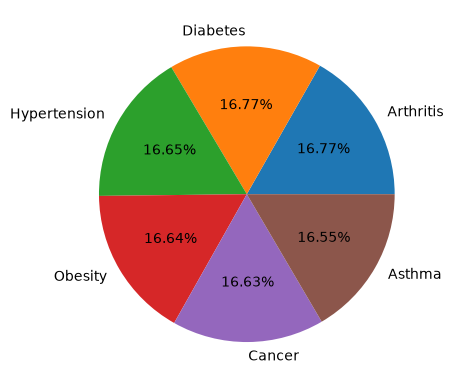

In [29]:
plt.pie(
    x=df['Medical Condition'].value_counts().head(10).values,
    labels=df['Medical Condition'].value_counts().head(10).index,
    autopct="%.2f%%"
)

plt.show()

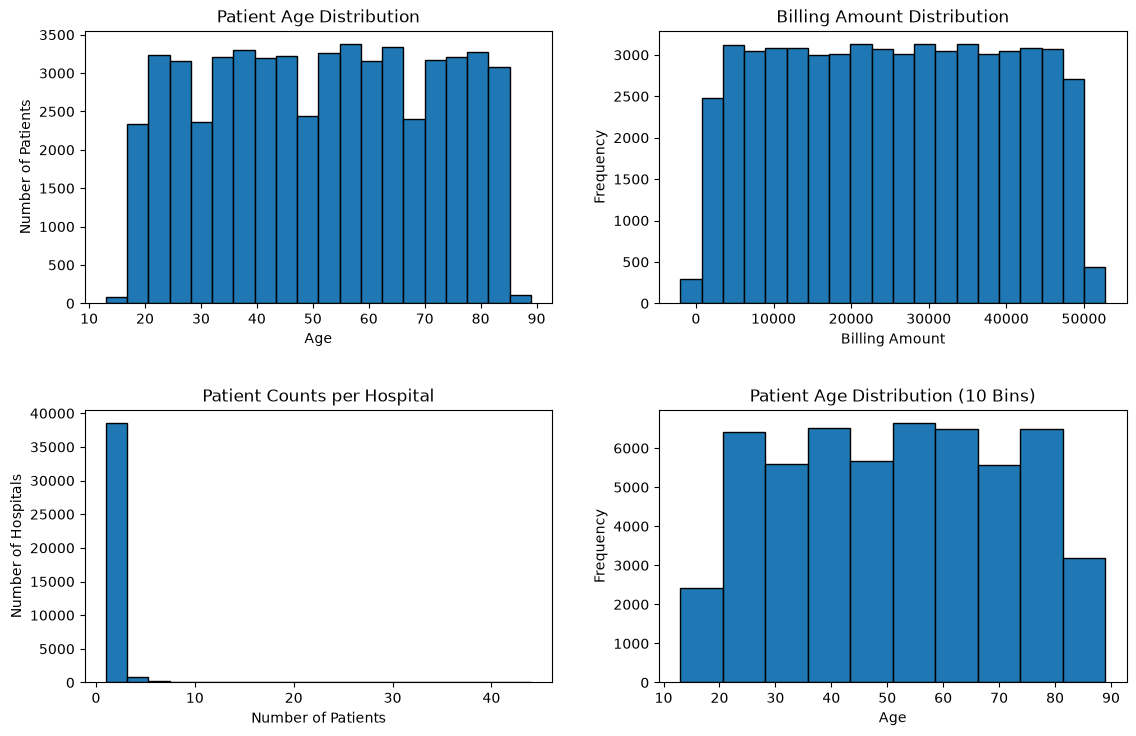

In [32]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.hist(df['Age'].dropna(), bins=20, edgecolor='black')
plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.subplot(2, 2, 2)
plt.hist(df['Billing Amount'].dropna(), bins=20, edgecolor='black')
plt.title("Billing Amount Distribution")
plt.xlabel("Billing Amount")
plt.ylabel("Frequency")

plt.subplot(2, 2, 3)
plt.hist(df['Hospital'].value_counts(), bins=20, edgecolor='black')
plt.title("Patient Counts per Hospital")
plt.xlabel("Number of Patients")
plt.ylabel("Number of Hospitals")

plt.subplot(2, 2, 4)
plt.hist(df['Age'].dropna(), bins=10, edgecolor='black')
plt.title("Patient Age Distribution (10 Bins)")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.tight_layout(pad=3.0)
plt.show()



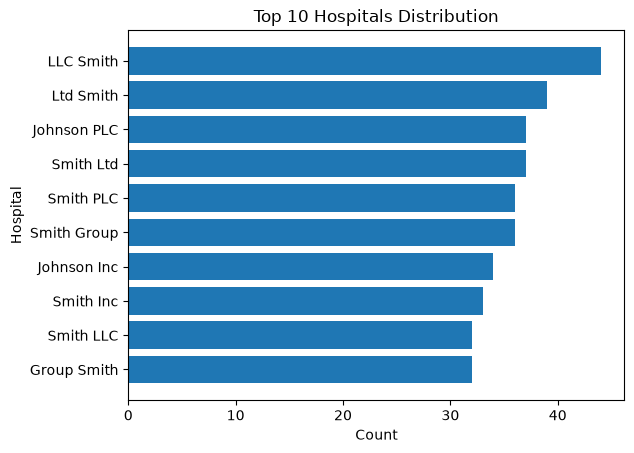

In [31]:
top_hospitals = df['Hospital'].value_counts().head(10)

plt.barh(top_hospitals.index[::-1], top_hospitals.values[::-1])

plt.title('Top 10 Hospitals Distribution')
plt.xlabel('Count')
plt.ylabel('Hospital')

plt.show()


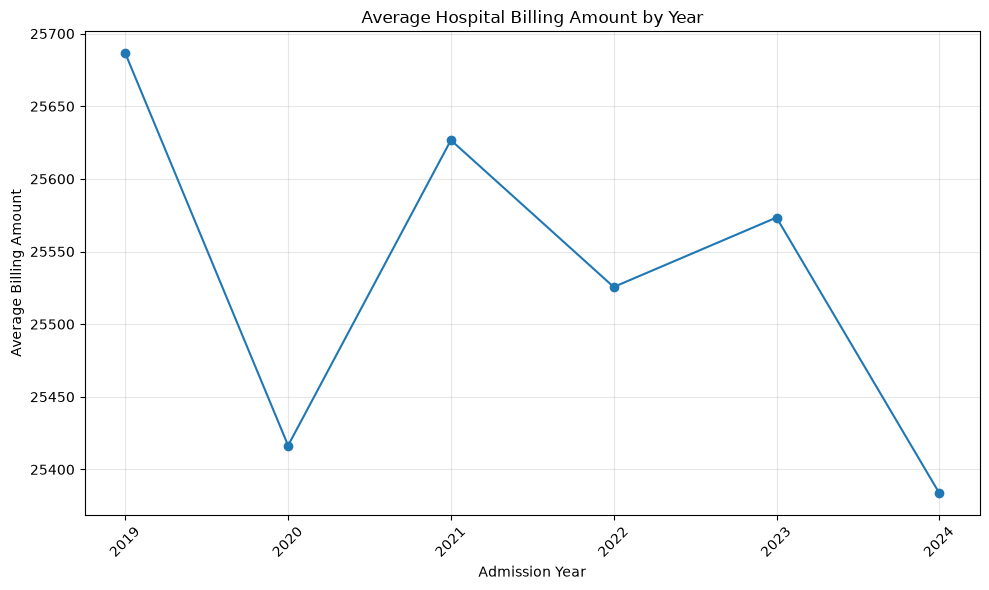

In [33]:
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'], errors='coerce')

year_based_billing = df.groupby(df['Date of Admission'].dt.year)['Billing Amount'].mean()

years = year_based_billing.index.astype(int).astype(str)

plt.figure(figsize=(10, 6))
plt.plot(years, year_based_billing.values, marker='o')

plt.title("Average Hospital Billing Amount by Year")
plt.xlabel("Admission Year")
plt.ylabel("Average Billing Amount")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
